# 08. Learning Rate Scheduler experiments

Ten etap ma na celu zbadać wpływ adaptacyjnego zmniejszania learning rate na skuteczność czterech konfiguracji fine-tuningu EfficientNet-B0.

## 1. Przygotowanie środowiska

In [1]:
import sys
from pathlib import Path

import tensorflow as tf
from tensorflow.keras import layers

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import json

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    f1_score,
    balanced_accuracy_score
)

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.image_pipeline import create_dataset
from src.utils import build_confusion_matrix, history_plot, test_aug, build_ft3_model, evaluate_per_class, build_augmentation

I0000 00:00:1795459007.188466    1889 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795459007.221741    1889 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795459008.846822    1889 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
import importlib
import src.utils

importlib.reload(src.utils)


<module 'src.utils' from '/mnt/c/users/nagor/OneDrive/Desktop/Praca/src/utils.py'>

In [3]:
print(f"Wersja tensorflow: {tf.__version__}")
print(f"Liczba wykrytych GPU: {len(tf.config.list_physical_devices('GPU'))}")
print(f"Zidentyfikowana karta graficzna: {tf.config.list_physical_devices('GPU')[0]}")

Wersja tensorflow: 2.21.0
Liczba wykrytych GPU: 1
Zidentyfikowana karta graficzna: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


W0000 00:00:1795459010.734943    1889 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.


### 1.2. Konfiguracja zmiennych globalnych

In [17]:
IMG_SIZE=(224,224)
BATCH_SIZE=32
SEED = 42
EPOCHS = 100
LEARNING_RATE=1e-4

tf.keras.utils.set_random_seed(SEED)

label_encoder = joblib.load("../dataset/label_encoder.joblib")
class_names = label_encoder.classes_

BASELINE_PATH = Path("../models/best_baseline_a0.keras")

RESULTS_DIR = Path("../models")
OUT_DIR = Path.joinpath(RESULTS_DIR, "08_experiments")

### 1.3. Wczytanie danych

In [5]:
train_df = pd.read_csv("../dataset/train_processed.csv")
val_df = pd.read_csv("../dataset/val_processed.csv")

train = create_dataset(
    train_df,
    training=True,
    BATCH_SIZE=BATCH_SIZE,
    IMG_SIZE=IMG_SIZE
)

val = create_dataset(
    val_df,
    training=False,
    BATCH_SIZE=BATCH_SIZE,
    IMG_SIZE=IMG_SIZE
)

print(f"Train: {len(train_df)}")
print(f"Validation: {len(val_df)}")

images, labels = next(iter(train))
print("Image batch:", images.shape)
print("Label batch:", labels.shape)

W0000 00:00:1795459010.781757    1889 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1795459010.923676    1889 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13209 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5070 Ti, pci bus id: 0000:01:00.0, compute capability: 12.0a


Train: 6409
Validation: 1602
Image batch: (32, 224, 224, 3)
Label batch: (32, 7)


### 1.4. Wczytanie wyników referencyjnych

In [43]:
REFERENCE_PATHS = {
    "FT3": Path("../models/05_finetuning/metrics.json"),
    "AUG1": Path("../models/06_experiments/AUG1/metrics.json"),
    "CW10": Path("../models/07_experiments/CW10/metrics.json"),
    "CW10_AUG1": Path("../models/06_experiments/CW_AUG1/metrics.json"),
}

In [44]:
def load_reference_results(paths):
    results = {}

    for exp_id, path in paths.items():
        if not path.exists():
            raise FileNotFoundError(
                f"Brak wyników dla {exp_id}: {path}"
            )

        with open(path, "r", encoding="utf-8") as f:
            results[exp_id] = json.load(f)
            print(f"{exp_id}: {results[exp_id]}")

    return results

In [45]:
reference_results = load_reference_results(REFERENCE_PATHS)
reference_df = pd.DataFrame.from_dict(
    reference_results,
    orient="index"
)

reference_df.index.name = "experiment"
display(reference_df.round(4))

FT3: {'val_f1_macro': 0.6819296921967178, 'val_accuracy': 0.817103620474407}
AUG1: {'experiment': 'AUG1', 'f1_macro': 0.652947723865509, 'accuracy': 0.7927590608596802, 'loss': 0.6335746049880981}
CW10: {'experiment': 'CW10', 'f1_macro': 0.6847243905067444, 'accuracy': 0.7821472883224487, 'loss': 0.6270059943199158}
CW10_AUG1: {'experiment': 'AUG1', 'f1_macro': 0.6397734880447388, 'accuracy': 0.7059925198554993, 'loss': 0.8028649091720581}


,val_f1_macro,val_accuracy,experiment,f1_macro,accuracy,loss
experiment,,,,,,
FT3,0.6819,0.8171,NaN,NaN,NaN,NaN
AUG1,NaN,NaN,AUG1,0.6529,0.7928,0.6336
CW10,NaN,NaN,CW10,0.6847,0.7821,0.6270
CW10_AUG1,NaN,NaN,AUG1,0.6398,0.7060,0.8029


## 2. Konfiguracja eksperymentów

In [6]:
y_train = train_df["dx_encoded"].to_numpy()

classes = np.arange(len(class_names))

balanced_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

balanced_weights = {
        int(cls): float(weight)
        for cls, weight in zip(classes, balanced_weights)
}

balanced_weights

{0: 4.380724538619275,
 1: 2.782891880156318,
 2: 1.3023775655354604,
 3: 12.542074363992173,
 4: 1.2841114005209378,
 5: 0.2133701767819689,
 6: 10.061224489795919}

In [7]:
EXPERIMENTS = {
    "LR_FT3": {
        "augmentation": None,
        "CW": None
    },
    "LR_AUG1": {
        "augmentation": "AUG1",
        "CW": None
    },
    "LR_CW10": {
        "augmentation": None,
        "CW": 1.0
    },
    "LR_CW10_AUG1": {
        "augmentation": "AUG1",
        "CW": 1.0
    }
}

In [8]:
def build_callbacks(exp_dir):
    return [
        tf.keras.callbacks.ModelCheckpoint(
            filepath=str(exp_dir / "best.keras"),
            monitor="val_f1_macro",
            mode="max",
            save_best_only=True
        ),

        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_f1_macro",
            mode="max",
            factor=0.5,
            patience=4,
            min_delta=0.001,
            min_lr=1e-7,
            verbose=1
        ),

        tf.keras.callbacks.EarlyStopping(
            monitor="val_f1_macro",
            mode="max",
            patience=12,
            min_delta=0.001,
            restore_best_weights=True
        )
    ]

### 2.1. Funkcja wywołująca eksperyment i trening

In [13]:
def run_experiment(experiment_id, augmentation_id, class_weight=None):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    
    model = build_ft3_model(
        BASELINE_PATH,
        (*IMG_SIZE, 3),
        augmentation= build_augmentation(augmentation_id),
        model_name=experiment_id
    )

    exp_dir = OUT_DIR / (experiment_id)
    exp_dir.mkdir(parents=True, exist_ok=True)

    callbacks = build_callbacks(exp_dir)
    
    history = model.fit(train, validation_data=val, epochs=EPOCHS,
                        callbacks=callbacks, verbose=1, class_weight=class_weight)  
    pd.DataFrame(history.history).to_csv(exp_dir / 'history.csv', index=False)

    results = model.evaluate(
        val,
        return_dict=True,
        verbose=0
    )
    
    metrics = {
        "experiment": experiment_id,
        "f1_macro": float(results["f1_macro"]),
        "accuracy": float(results["accuracy"]),
        "loss": float(results["loss"])
    }
    
    (exp_dir / "metrics.json").write_text(
        json.dumps(metrics, indent=2),
        encoding="utf-8"
    )
    return metrics

In [18]:
results = []
for exp_id, config in EXPERIMENTS.items():
    CW = balanced_weights if config["CW"] is not None else None
    results.append(
        run_experiment(exp_id, config["augmentation"] , CW)
                  )

Epoch 1/100


/home/nagorny/miniconda3/envs/tf_gpu_wsl/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1795460072.902071    2042 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_317747__.260


199/201 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8130 - f1_macro: 0.6961 - loss: 0.4975

I0000 00:00:1795460082.935805    2053 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_317747__.260


201/201 ━━━━━━━━━━━━━━━━━━━━ 29s 87ms/step - accuracy: 0.8129 - f1_macro: 0.6965 - loss: 0.4983 - val_accuracy: 0.7890 - val_f1_macro: 0.6187 - val_loss: 0.5877 - learning_rate: 1.0000e-05
Epoch 2/100
201/201 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - accuracy: 0.8299 - f1_macro: 0.7103 - loss: 0.4630 - val_accuracy: 0.7896 - val_f1_macro: 0.6325 - val_loss: 0.5779 - learning_rate: 1.0000e-05
Epoch 3/100
201/201 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - accuracy: 0.8274 - f1_macro: 0.7276 - loss: 0.4554 - val_accuracy: 0.7971 - val_f1_macro: 0.6521 - val_loss: 0.5735 - learning_rate: 1.0000e-05
Epoch 4/100
201/201 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - accuracy: 0.8429 - f1_macro: 0.7495 - loss: 0.4282 - val_accuracy: 0.7965 - val_f1_macro: 0.6595 - val_loss: 0.5686 - learning_rate: 1.0000e-05
Epoch 5/100
201/201 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - accuracy: 0.8557 - f1_macro: 0.7747 - loss: 0.4030 - val_accuracy: 0.7971 - val_f1_macro: 0.6381 - val_loss: 0.5704 - learning_rate: 1.0000e-05
Epoch 6/100

/home/nagorny/miniconda3/envs/tf_gpu_wsl/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
E0000 00:00:1795460242.220730    1889 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/LR_AUG1_1/functional_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


... (3 outputs left out)

I0000 00:00:1795460453.041673    2036 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_460698__.260


201/201 ━━━━━━━━━━━━━━━━━━━━ 30s 91ms/step - accuracy: 0.7408 - f1_macro: 0.6188 - loss: 0.6695 - val_accuracy: 0.7160 - val_f1_macro: 0.5628 - val_loss: 0.7572 - learning_rate: 1.0000e-05
Epoch 2/100
201/201 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - accuracy: 0.7441 - f1_macro: 0.6287 - loss: 0.5935 - val_accuracy: 0.7135 - val_f1_macro: 0.5538 - val_loss: 0.7446 - learning_rate: 1.0000e-05
Epoch 3/100
201/201 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - accuracy: 0.7401 - f1_macro: 0.6267 - loss: 0.5778 - val_accuracy: 0.7185 - val_f1_macro: 0.5827 - val_loss: 0.7437 - learning_rate: 1.0000e-05
Epoch 4/100
201/201 ━━━━━━━━━━━━━━━━━━━━ 6s 27ms/step - accuracy: 0.7560 - f1_macro: 0.6581 - loss: 0.5331 - val_accuracy: 0.7285 - val_f1_macro: 0.6083 - val_loss: 0.7299 - learning_rate: 1.0000e-05
Epoch 5/100
201/201 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - accuracy: 0.7717 - f1_macro: 0.6699 - loss: 0.5252 - val_accuracy: 0.7391 - val_f1_macro: 0.6127 - val_loss: 0.6905 - learning_rate: 1.0000e-05
Epoch 6/100

/home/nagorny/miniconda3/envs/tf_gpu_wsl/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
E0000 00:00:1795460701.711850    1889 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/LR_CW10_AUG1_1/functional_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


201/201 ━━━━━━━━━━━━━━━━━━━━ 18s 57ms/step - accuracy: 0.6783 - f1_macro: 0.4989 - loss: 0.9589 - val_accuracy: 0.6323 - val_f1_macro: 0.5180 - val_loss: 0.9703 - learning_rate: 1.0000e-05
Epoch 2/100
201/201 ━━━━━━━━━━━━━━━━━━━━ 9s 43ms/step - accuracy: 0.6806 - f1_macro: 0.5316 - loss: 0.7898 - val_accuracy: 0.6348 - val_f1_macro: 0.5579 - val_loss: 0.9459 - learning_rate: 1.0000e-05
Epoch 3/100
201/201 ━━━━━━━━━━━━━━━━━━━━ 10s 50ms/step - accuracy: 0.6881 - f1_macro: 0.5535 - loss: 0.7408 - val_accuracy: 0.6273 - val_f1_macro: 0.5625 - val_loss: 0.9871 - learning_rate: 1.0000e-05
Epoch 4/100
201/201 ━━━━━━━━━━━━━━━━━━━━ 10s 49ms/step - accuracy: 0.7068 - f1_macro: 0.5737 - loss: 0.7225 - val_accuracy: 0.6342 - val_f1_macro: 0.5547 - val_loss: 0.9746 - learning_rate: 1.0000e-05
Epoch 5/100
201/201 ━━━━━━━━━━━━━━━━━━━━ 11s 52ms/step - accuracy: 0.7093 - f1_macro: 0.5880 - loss: 0.6889 - val_accuracy: 0.6648 - val_f1_macro: 0.5665 - val_loss: 0.8988 - learning_rate: 1.0000e-05
Epoch 6/

In [19]:
results

[{'experiment': 'LR_FT3',
  'f1_macro': 0.6787334680557251,
  'accuracy': 0.8108614087104797,
  'loss': 0.5611838102340698},
 {'experiment': 'LR_AUG1',
  'f1_macro': 0.6380301713943481,
  'accuracy': 0.784019947052002,
  'loss': 0.5983995795249939},
 {'experiment': 'LR_CW10',
  'f1_macro': 0.6710349321365356,
  'accuracy': 0.7709113359451294,
  'loss': 0.6372752785682678},
 {'experiment': 'LR_CW10_AUG1',
  'f1_macro': 0.632503092288971,
  'accuracy': 0.692259669303894,
  'loss': 0.8217928409576416}]

## 3. Analiza wyników

In [46]:
scheduler_results = {}

for exp_id in EXPERIMENTS:
    path = OUT_DIR / exp_id / "metrics.json"

    with open(path, "r", encoding="utf-8") as f:
        scheduler_results[exp_id] = json.load(f)


MODEL_PAIRS = {
    "LR_FT3": "FT3",
    "LR_AUG1": "AUG1",
    "LR_CW10": "CW10",
    "LR_CW10_AUG1": "CW10_AUG1"
}

comparison = []

for scheduler_id, reference_id in MODEL_PAIRS.items():

    reference = reference_results[reference_id]
    scheduler = scheduler_results[scheduler_id]

    f1_reference = reference.get(
        "f1_macro",
        reference.get("val_f1_macro")
    )

    accuracy_reference = reference.get(
        "accuracy",
        reference.get("val_accuracy")
    )

    comparison.append({
        "Model": reference_id,
        "F1 reference": f1_reference,
        "F1 scheduler": scheduler["f1_macro"],
        "Accuracy reference": accuracy_reference,
        "Accuracy scheduler": scheduler["accuracy"],
    })

comparison_df = pd.DataFrame(comparison)

comparison_df["delta F1"] = (
    comparison_df["F1 scheduler"]
    - comparison_df["F1 reference"]
)

comparison_df["delta Accuracy"] = (
    comparison_df["Accuracy scheduler"]
    - comparison_df["Accuracy reference"]
)

display(comparison_df.round(4))

,Model,F1 reference,F1 scheduler,Accuracy reference,Accuracy scheduler,delta F1,delta Accuracy
0,FT3,0.6819,0.6787,0.8171,0.8109,-0.0032,-0.0062
1,AUG1,0.6529,0.6380,0.7928,0.7840,-0.0149,-0.0087
2,CW10,0.6847,0.6710,0.7821,0.7709,-0.0137,-0.0112
3,CW10_AUG1,0.6398,0.6325,0.7060,0.6923,-0.0073,-0.0137


### 5.2. Analiza przebiegu learning rate [AAAAAAAAAAAAAAAAAA]

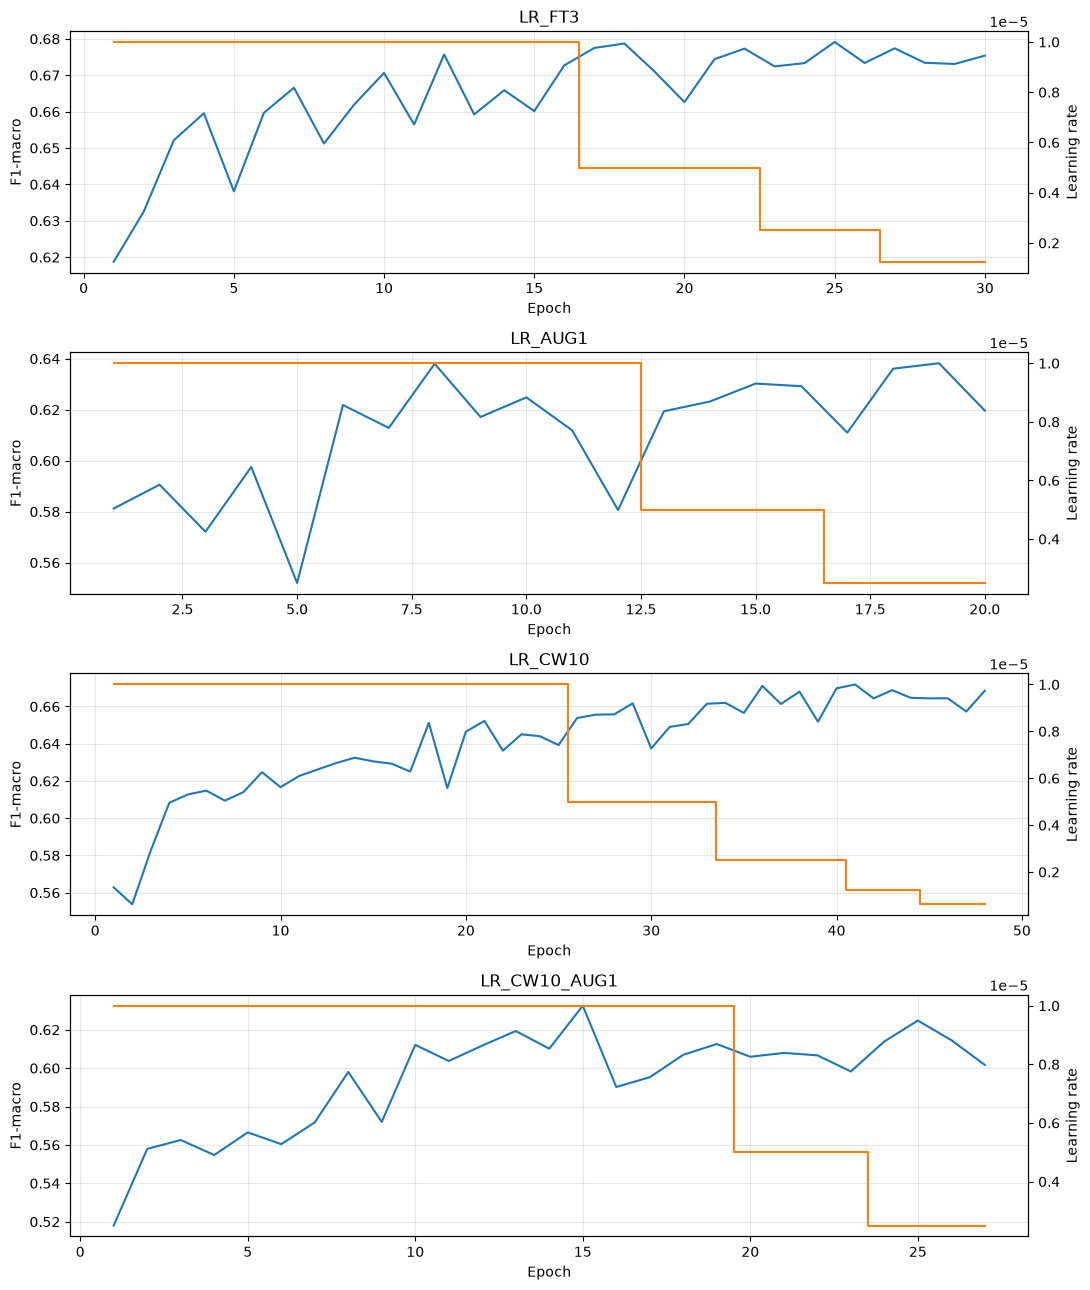

In [57]:
fig, axes = plt.subplots(
    len(EXPERIMENTS), 1,
    figsize=(11, 13)
)

for ax, exp_id in zip(axes, EXPERIMENTS):
    history = pd.read_csv(OUT_DIR / exp_id / "history.csv")
    epochs = np.arange(1, len(history) + 1)

    ax.plot(
        epochs,
        history["val_f1_macro"],
        color="tab:blue",
        label="Validation F1-macro"
    )

    ax.set(
        title=exp_id,
        xlabel="Epoch",
        ylabel="F1-macro"
    )
    ax.grid(alpha=0.3)

    ax_lr = ax.twinx()
    ax_lr.step(
        epochs,
        history["learning_rate"],
        where="mid",
        color="tab:orange",
        label="Learning rate"
    )
    ax_lr.set_ylabel("Learning rate")
    ax_lr.ticklabel_format(
        axis="y", style="sci", scilimits=(0, 0)
    )

plt.tight_layout()
plt.show()

### 5.3. Analiza przebiegu uczenia


Experiment: LR_FT3


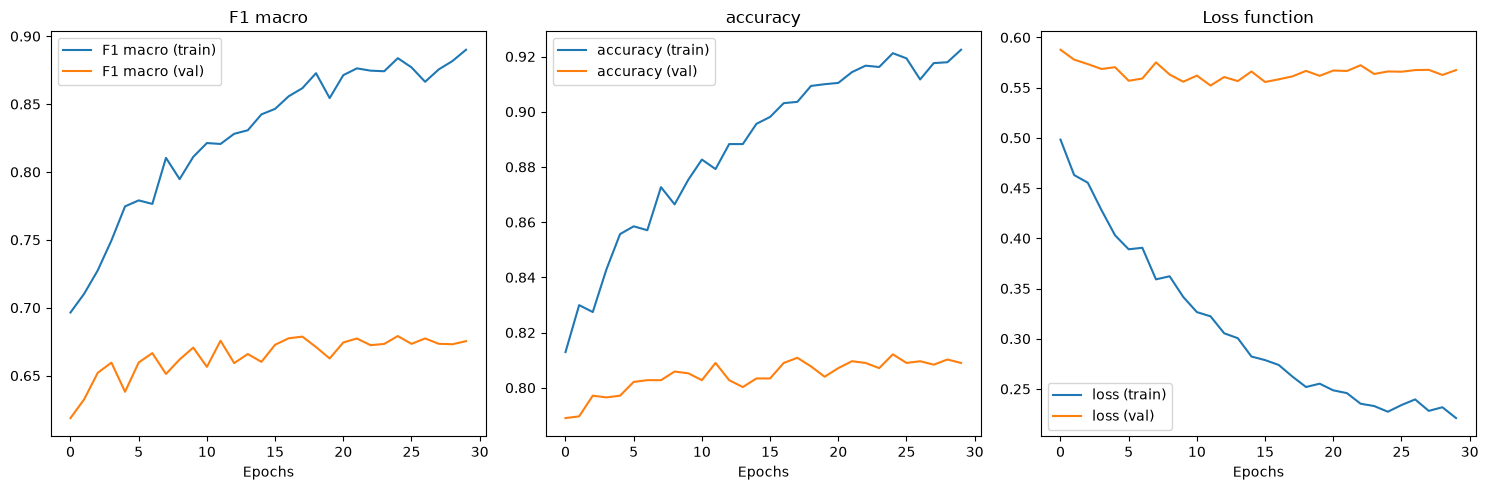


Experiment: LR_AUG1


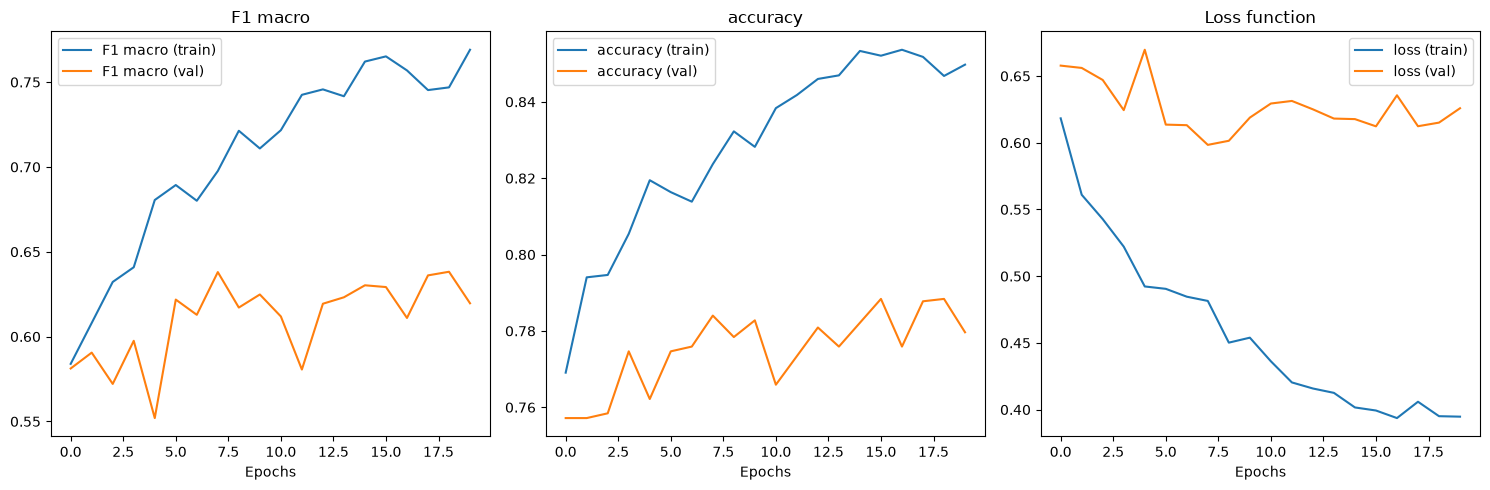


Experiment: LR_CW10


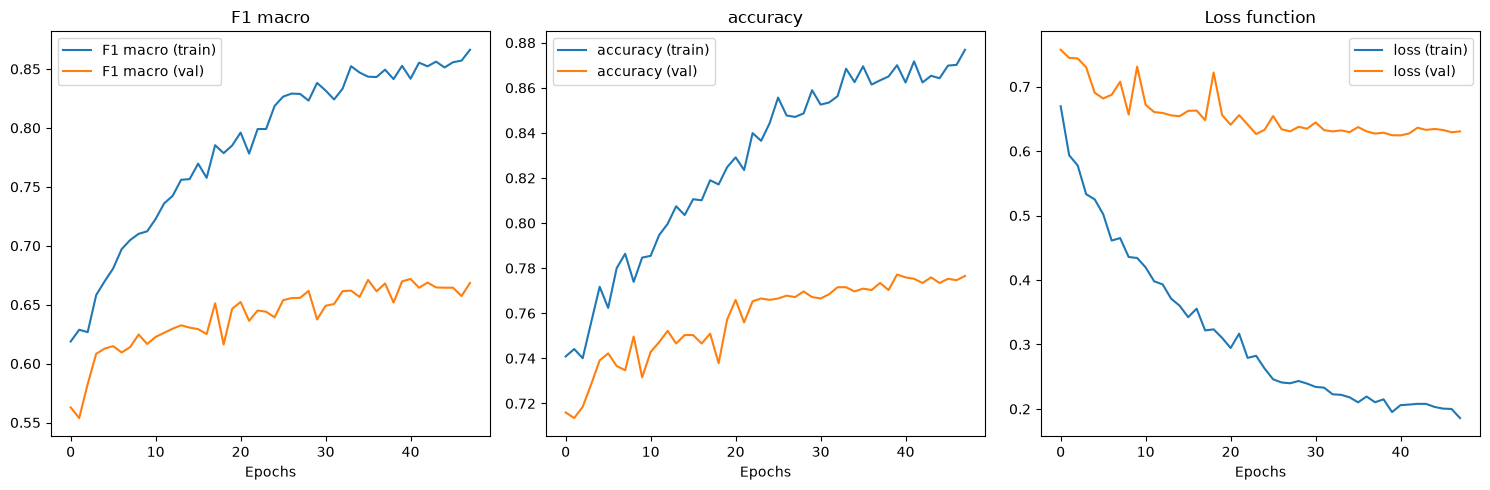


Experiment: LR_CW10_AUG1


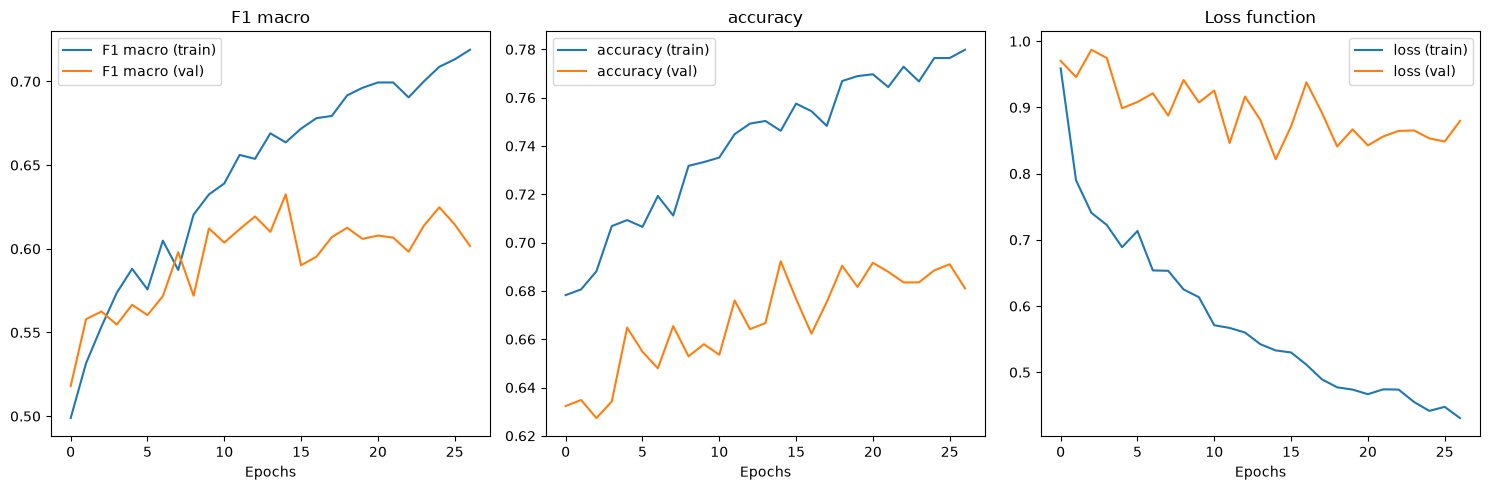

In [47]:
for exp_id in EXPERIMENTS:

    history = pd.read_csv(
        OUT_DIR / exp_id / "history.csv"
    )

    print(f"\nExperiment: {exp_id}")

    history_plot(history)

### 5.4. Macierze pomyłek

51/51 ━━━━━━━━━━━━━━━━━━━━ 6s 73ms/step


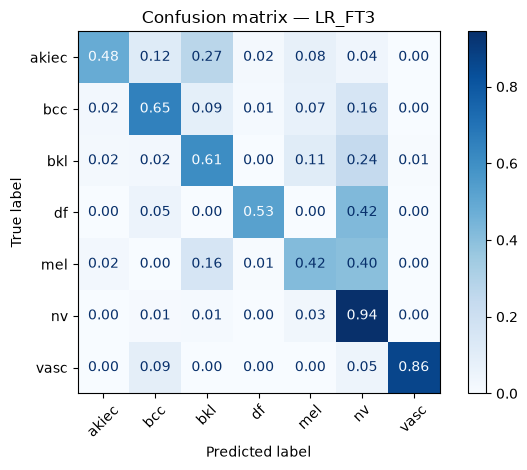

51/51 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step


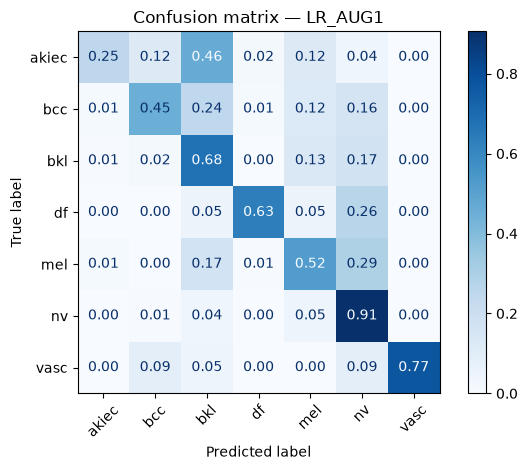

51/51 ━━━━━━━━━━━━━━━━━━━━ 6s 71ms/step


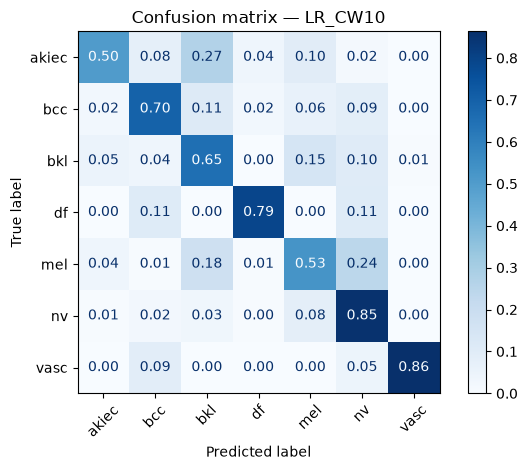

51/51 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step


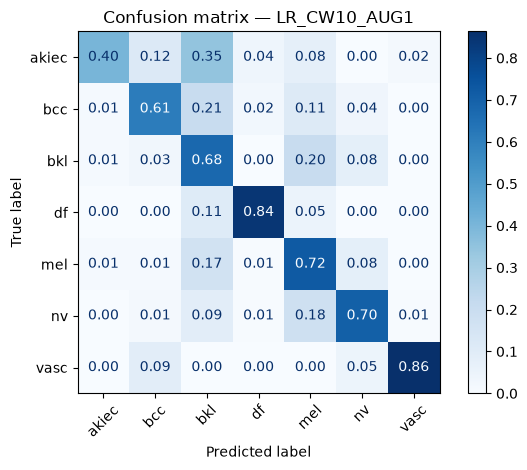

In [48]:
confusion_matrices = {}

for exp_id in EXPERIMENTS:

    model_path = OUT_DIR / exp_id / "best.keras"

    model = tf.keras.models.load_model(
        model_path,
        compile=False
    )

    cm, cm_display = build_confusion_matrix(
        model,
        val,
        class_names
    )

    confusion_matrices[exp_id] = cm

    cm_display.plot(
        cmap="Blues",
        xticks_rotation=45,
        values_format=".2f"
    )

    plt.title(f"Confusion matrix — {exp_id}")
    plt.tight_layout()
    plt.show()

    del model

### 5.5. Porównanie macierzy pomyłek najlepszego modelu z odpowiednikiem bez LR schedulera

51/51 ━━━━━━━━━━━━━━━━━━━━ 7s 76ms/step


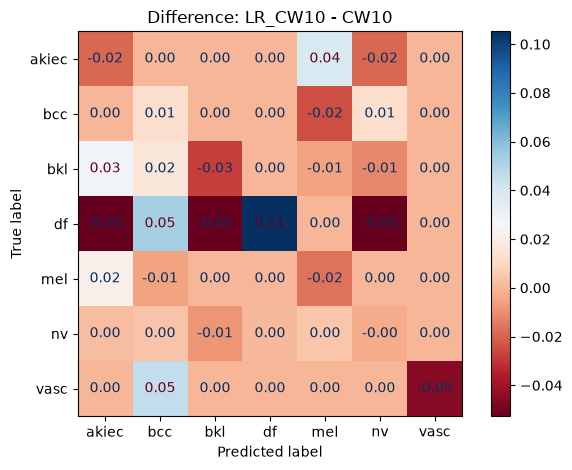

In [54]:
model = tf.keras.models.load_model("../models/07_experiments/CW10/best.keras", compile=False)

cm, _ = build_confusion_matrix(model, val, class_names)
cm_scheduler = confusion_matrices['LR_CW10']
cm_diff = cm_scheduler - cm

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm_diff,
    display_labels=class_names
)

display_cm.plot(cmap="RdBu", values_format=".2f",)

plt.title(f"Difference: LR_CW10 - CW10")
plt.tight_layout()
plt.show()

### 5.6. Precision, recall, F1-score per klasa

In [56]:
cw10_model = tf.keras.models.load_model(
    "../models/07_experiments/CW10/best.keras",
    compile=False
)

lr_cw10_model = tf.keras.models.load_model(
    OUT_DIR / "LR_CW10" / "best.keras",
    compile=False
)

cw10_report = evaluate_per_class(cw10_model, val, class_names)
lr_cw10_report = evaluate_per_class(lr_cw10_model, val, class_names)

per_class_comparison = pd.DataFrame(index=class_names)

for metric in ["precision", "recall", "f1-score"]:
    per_class_comparison[f"{metric}_CW10"] = cw10_report[metric]
    per_class_comparison[f"{metric}_LR_CW10"] = lr_cw10_report[metric]

    per_class_comparison[f"delta_{metric}"] = (
        lr_cw10_report[metric] - cw10_report[metric]
    )

display(per_class_comparison.round(3))

,precision_CW10,precision_LR_CW10,delta_precision,recall_CW10,recall_LR_CW10,delta_recall,f1-score_CW10,f1-score_LR_CW10,delta_f1-score
akiec,0.659,0.520,-0.139,0.519,0.500,-0.019,0.581,0.510,-0.071
bcc,0.651,0.600,-0.051,0.683,0.695,0.012,0.667,0.644,-0.023
bkl,0.543,0.558,0.015,0.682,0.653,-0.028,0.605,0.602,-0.002
df,0.619,0.625,0.006,0.684,0.789,0.105,0.650,0.698,0.048
mel,0.449,0.433,-0.016,0.545,0.528,-0.017,0.492,0.476,-0.016
nv,0.925,0.927,0.003,0.857,0.855,-0.003,0.890,0.889,-0.000
vasc,0.909,0.905,-0.004,0.909,0.864,-0.045,0.909,0.884,-0.025


## 6. Wnioski

**1. Wpływ schedulera na skuteczność klasyfikacji**

- Zastosowanie `ReduceLROnPlateau` nie poprawiło F1-macro w żadnej z czterech badanych konfiguracji.
- Najmniejszy spadek odnotowano dla `LR_FT3` (−0,0032), natomiast największy dla `LR_AUG1` (−0,0149).
- Najlepszy model ze schedulerem (`LR_FT3`) uzyskał F1-macro = **0,6787**, nieznacznie poniżej referencyjnego FT3 (0,6819).
- Wyniki nie wskazują na korzyść z zastosowania schedulera w badanych konfiguracjach.

**2. Wpływ schedulera na proces uczenia**

- Scheduler prawidłowo reagował na stagnację walidacyjnego F1-macro, stopniowo zmniejszając learning rate.
- W wybranych eksperymentach po redukcji LR obserwowano niewielkie poprawy F1-macro, jednak nie przełożyły się one na uzyskanie lepszych wyników niż w modelach referencyjnych.
- Widoczna różnica pomiędzy treningowym i walidacyjnym F1-macro oraz dalszy spadek treningowego loss przy stabilizacji walidacyjnego loss wskazują na utrzymujące się oznaki przeuczenia.
- Samo adaptacyjne zmniejszanie learning rate okazało się niewystarczające do ograniczenia tego zjawiska.

**3. Wpływ na rozpoznawanie poszczególnych klas**

- Analiza macierzy pomyłek wykazała, że scheduler wpływał na rozkład błędów pomiędzy klasami, jednak zmiany nie miały jednoznacznie korzystnego charakteru.
- W konfiguracji `LR_CW10` zaobserwowano poprawę recall klasy `df`, przy jednoczesnym pogorszeniu wyników części pozostałych klas.
- Ważenie klas pozwala ograniczyć dominację klasy `nv` w predykcjach, jednak wiąże się z kompromisem pomiędzy rozpoznawaniem klas mniejszościowych a poprawnością klasyfikacji klasy większościowej.
- Oceniając skuteczność modelu, należy uwzględniać zarówno recall, jak i precision, ponieważ zwiększenie liczby predykcji klas mniejszościowych nie musi oznaczać poprawy jakości klasyfikacji.

**4. Wybór modelu końcowego**

- Do dalszej oceny wybrano model **CW10**, wykorzystujący ważenie klas bez augmentacji i bez LR schedulera.
- Model osiągnął najwyższy spośród porównywanych wariantów F1-macro = **0,6847**, przy accuracy = **0,7821**.
- W porównaniu z FT3 model CW10 charakteryzuje się mniejszą dominacją klasy `nv` w predykcjach, co jest pożądane przy silnie niezrównoważonym rozkładzie klas.
- Wybór CW10 uzasadnia nie tylko wartość F1-macro, ale również bardziej zrównoważone podejście do rozpoznawania poszczególnych kategorii zmian skórnych.
- Należy jednak uwzględnić niższą accuracy i możliwość zwiększenia liczby błędnych predykcji klas mniejszościowych.
- Ostateczna skuteczność wybranego modelu zostanie oceniona na wydzielonym zbiorze testowym, który nie uczestniczył w doborze hiperparametrów ani wyborze konfiguracji modelu.